#### 1. Latihan Data Loading
Pada tahap ini dilakukan proses pemuatan dataset menggunakan library Pandas. Dataset terdiri dari data latih (`train.csv`) dan data uji (`test.csv`). Pemeriksaan awal dilakukan untuk mengetahui jumlah baris dan kolom serta memahami struktur dan tipe data yang digunakan.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

test = pd.read_csv("content/test.csv")
train = pd.read_csv("content/train.csv")

train.head()

,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900
3,3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000
4,4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500


In [2]:
print("Jumlah data train:", train.shape)
print("Jumlah data test:", test.shape)

Jumlah data train: (188533, 13)
Jumlah data test: (125690, 12)


#### Kesimpulan Data Loading

Dataset Car Prices berhasil dimuat menggunakan Pandas. Data `train` memiliki 188.533 baris dan 13 kolom, sedangkan `test` memiliki 125.690 baris dan 12 kolom. Kedua dataset siap digunakan untuk tahap berikutnya.

#### 2. Latihan: Data Cleaning dan Transformation

Pada tahap ini dilakukan pemeriksaan kualitas dataset untuk mengetahui informasi setiap kolom, tipe data, serta jumlah nilai yang tersedia. Pemeriksaan ini menjadi langkah awal untuk menentukan proses pembersihan dan transformasi data yang diperlukan.

In [30]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 188533 entries, 0 to 188532
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   id            188533 non-null  int64
 1   brand         188533 non-null  str  
 2   model         188533 non-null  str  
 3   model_year    188533 non-null  int64
 4   milage        188533 non-null  int64
 5   fuel_type     188533 non-null  str  
 6   engine        188533 non-null  str  
 7   transmission  188533 non-null  str  
 8   ext_col       188533 non-null  str  
 9   int_col       188533 non-null  str  
 10  accident      188533 non-null  str  
 11  clean_title   188533 non-null  str  
 12  price         188533 non-null  int64
dtypes: int64(4), str(9)
memory usage: 18.7 MB


In [4]:
train.describe()

,id,model_year,milage,price
count,188533.000000,188533.000000,188533.000000,1.885330e+05
mean,94266.000000,2015.829998,65705.295174,4.387802e+04
std,54424.933488,5.660967,49798.158076,7.881952e+04
min,0.000000,1974.000000,100.000000,2.000000e+03
25%,47133.000000,2013.000000,24115.000000,1.700000e+04
50%,94266.000000,2017.000000,57785.000000,3.082500e+04
75%,141399.000000,2020.000000,95400.000000,4.990000e+04
max,188532.000000,2024.000000,405000.000000,2.954083e+06


In [5]:
train.describe(include="all")

,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
count,188533.000000,188533,188533,188533.000000,188533.000000,183450,188533,188533,188533,188533,186081,167114,1.885330e+05
unique,NaN,57,1897,NaN,NaN,7,1117,52,319,156,2,1,NaN
top,NaN,Ford,F-150 XLT,NaN,NaN,Gasoline,355.0HP 5.3L 8 Cylinder Engine Gasoline Fuel,A/T,Black,Black,None reported,Yes,NaN
freq,NaN,23088,2945,NaN,NaN,165940,3462,49904,48658,107674,144514,167114,NaN
mean,94266.000000,NaN,NaN,2015.829998,65705.295174,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.387802e+04
std,54424.933488,NaN,NaN,5.660967,49798.158076,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.881952e+04
min,0.000000,NaN,NaN,1974.000000,100.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000e+03
25%,47133.000000,NaN,NaN,2013.000000,24115.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.700000e+04
50%,94266.000000,NaN,NaN,2017.000000,57785.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.082500e+04
75%,141399.000000,NaN,NaN,2020.000000,95400.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.990000e+04


In [6]:
# Memeriksa jumlah missing values pada setiap kolom
train.isnull().sum()

id                  0
brand               0
model               0
model_year          0
milage              0
fuel_type        5083
engine              0
transmission        0
ext_col             0
int_col             0
accident         2452
clean_title     21419
price               0
dtype: int64

In [7]:
# Menghitung persentase missing values
missing_percent = (train.isnull().sum() / len(train)) * 100

missing_percent.sort_values(ascending=False)

clean_title     11.360876
fuel_type        2.696080
accident         1.300568
brand            0.000000
id               0.000000
milage           0.000000
model_year       0.000000
model            0.000000
engine           0.000000
ext_col          0.000000
transmission     0.000000
int_col          0.000000
price            0.000000
dtype: float64

#### Mengatasi Missing Value

Disini kolom yang memiliki nilai kosong dipisahkan berdasarkan persentase missing values. Kolom dengan nilai kosong kurang dari 75% akan dipertimbangkan untuk diisi, sedangkan kolom dengan nilai kosong mencapai atau melebihi 75% akan dipertimbangkan untuk dihapus.

In [8]:
# Memisahkan kolom berdasarkan persentase missing values
missing_values = train.isnull().sum()

threshold = len(train) * 0.75

less = missing_values[missing_values < threshold].index
over = missing_values[missing_values >= threshold].index

print("Kolom dengan missing values di bawah 75%:")
print(missing_values[less][missing_values[less] > 0])

print("\nKolom dengan missing values mencapai atau melebihi 75%:")
print(missing_values[over][missing_values[over] > 0])

Kolom dengan missing values di bawah 75%:
fuel_type       5083
accident        2452
clean_title    21419
dtype: int64

Kolom dengan missing values mencapai atau melebihi 75%:
Series([], dtype: int64)


#### Mengisi Missing Values pada Kolom Numerik

Pada tahap ini, nilai kosong pada kolom numerik akan diisi menggunakan nilai median dari masing-masing kolom. Median dipilih agar pengisian nilai kosong tidak terlalu dipengaruhi oleh nilai ekstrem.

In [9]:
# Memilih kolom numerik yang memiliki missing values di bawah ambang batas
numeric_features = train[less].select_dtypes(include=["number"]).columns

# Mengisi missing values dengan median
train[numeric_features] = train[numeric_features].fillna(
    train[numeric_features].median()
)

print("Kolom numerik yang diproses:")
print(list(numeric_features))

Kolom numerik yang diproses:
['id', 'model_year', 'milage', 'price']


In [10]:
# Memilih kolom kategorikal
categorical_features = train[less].select_dtypes(
    include=["object"]
).columns

# Mengisi missing values dengan modus
for column in categorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

print("Kolom kategorikal yang diproses:")
print(list(categorical_features))

C:\Users\jun\AppData\Local\Temp\ipykernel_13776\3911516784.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = train[less].select_dtypes(


Kolom kategorikal yang diproses:
['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']


In [11]:
# Memeriksa missing values setelah proses pengisian
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

#### Mengatasi Outliers

Pada tahap ini dilakukan pemeriksaan outlier menggunakan metode Interquartile Range (IQR). Outlier merupakan nilai yang berada jauh di luar rentang umum data. Pemeriksaan dilakukan menggunakan boxplot untuk mengetahui apakah terdapat nilai ekstrem pada fitur numerik.

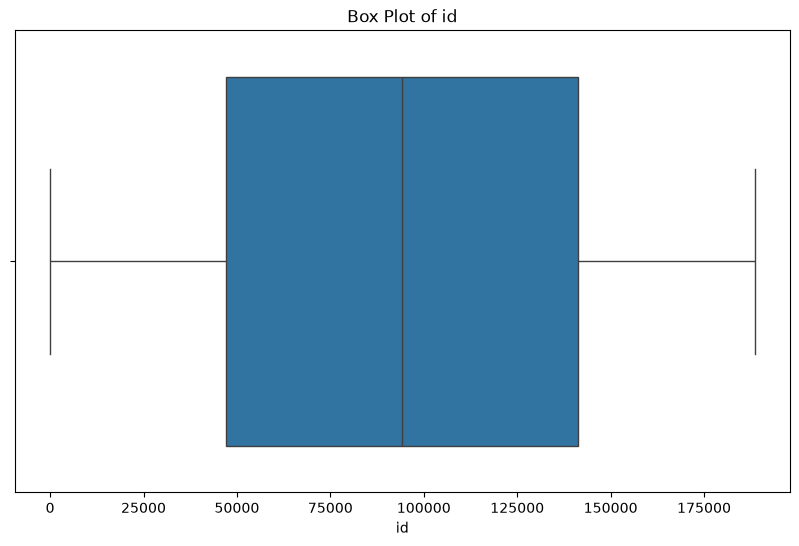

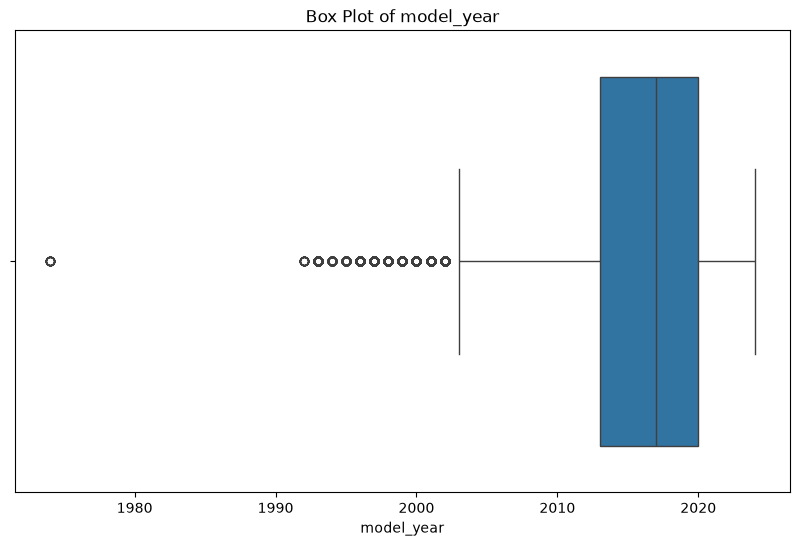

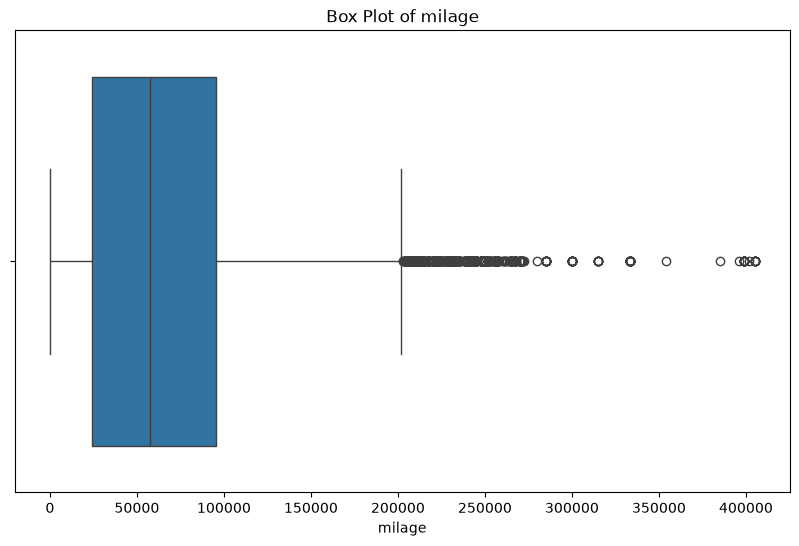

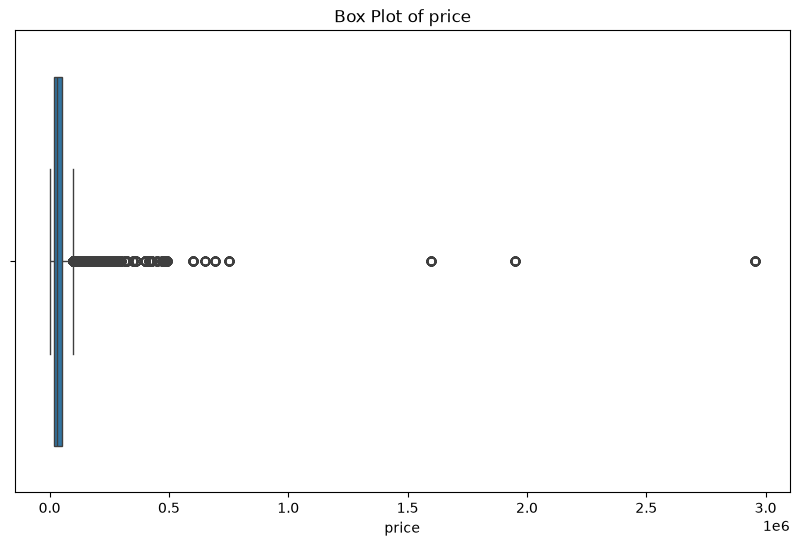

In [12]:
# Menampilkan boxplot untuk setiap fitur numerik
for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=train[feature])
    plt.title(f"Box Plot of {feature}")
    plt.show()

In [13]:
# Menghitung Q1, Q3, dan IQR
Q1 = train[numeric_features].quantile(0.25)
Q3 = train[numeric_features].quantile(0.75)

IQR = Q3 - Q1

print("Q1:")
print(Q1)

print("\nQ3:")
print(Q3)

print("\nIQR:")
print(IQR)

Q1:
id            47133.0
model_year     2013.0
milage        24115.0
price         17000.0
Name: 0.25, dtype: float64

Q3:
id            141399.0
model_year      2020.0
milage         95400.0
price          49900.0
Name: 0.75, dtype: float64

IQR:
id            94266.0
model_year        7.0
milage        71285.0
price         32900.0
dtype: float64


In [14]:
# Memilih fitur numerik yang relevan untuk pemeriksaan outlier
outlier_features = ["model_year", "milage", "price"]

# Menghitung Q1, Q3, dan IQR tanpa kolom id
Q1 = train[outlier_features].quantile(0.25)
Q3 = train[outlier_features].quantile(0.75)
IQR = Q3 - Q1

# Menghitung batas bawah dan batas atas
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Batas bawah:")
print(lower_bound)

print("\nBatas atas:")
print(upper_bound)

Batas bawah:
model_year     2002.5
milage       -82812.5
price        -32350.0
dtype: float64

Batas atas:
model_year      2030.5
milage        202327.5
price          99250.0
dtype: float64


In [15]:
# Mendeteksi baris yang memiliki outlier
condition_outlier = (
    (train[outlier_features] < lower_bound) |
    (train[outlier_features] > upper_bound)
)

# Menghitung jumlah outlier pada setiap kolom
print("Jumlah outlier per kolom:")
print(condition_outlier.sum())

# Menghitung jumlah baris yang memiliki minimal satu outlier
print("\nJumlah baris yang memiliki outlier:")
print(condition_outlier.any(axis=1).sum())

Jumlah outlier per kolom:
model_year     5132
milage         1766
price         10880
dtype: int64

Jumlah baris yang memiliki outlier:
17326


#### Menghapus Outliers Menggunakan Metode IQR

Disini, baris yang memiliki nilai di luar batas bawah atau batas atas IQR pada fitur numerik yang dipilih akan disaring. Hasil penyaringan disimpan dalam DataFrame baru agar data sebelum dan sesudah penanganan outlier dapat dibandingkan.

In [16]:
# Menentukan baris yang tidak memiliki outlier
condition = ~condition_outlier.any(axis=1)

# Membuat DataFrame baru tanpa baris kandidat outlier
df = train.loc[condition].copy()

print("Jumlah data sebelum penanganan outlier:", len(train))
print("Jumlah data setelah penanganan outlier:", len(df))
print("Jumlah baris yang disaring:", len(train) - len(df))

Jumlah data sebelum penanganan outlier: 188533
Jumlah data setelah penanganan outlier: 171207
Jumlah baris yang disaring: 17326


#### Normalisasi dan Standardisasi Data

Standardisasi merupakan proses mengubah skala fitur numerik agar memiliki rata-rata mendekati 0 dan standar deviasi mendekati 1. Pada tahap ini, standardisasi dilakukan menggunakan `StandardScaler` dari Scikit-learn pada fitur numerik yang telah melalui proses penanganan outlier.

In [17]:
from sklearn.preprocessing import StandardScaler

# Memilih fitur numerik tanpa kolom id
numeric_features = ["model_year", "milage", "price"]

# Membuat salinan DataFrame untuk standardisasi
df_scaled = df.copy()

# Melakukan standardisasi
scaler = StandardScaler()
df_scaled[numeric_features] = scaler.fit_transform(
    df_scaled[numeric_features]
)

df_scaled[numeric_features].describe()

,model_year,milage,price
count,1.712070e+05,1.712070e+05,1.712070e+05
mean,-1.694459e-14,-1.299012e-16,1.328063e-18
std,1.000003e+00,1.000003e+00,1.000003e+00
min,-2.630181e+00,-1.417306e+00,-1.507536e+00
25%,-6.246245e-01,-8.576120e-01,-8.039984e-01
50%,1.775981e-01,-1.345696e-01,-1.943596e-01
75%,7.792651e-01,6.259658e-01,5.561744e-01
max,1.581488e+00,2.946902e+00,3.042007e+00


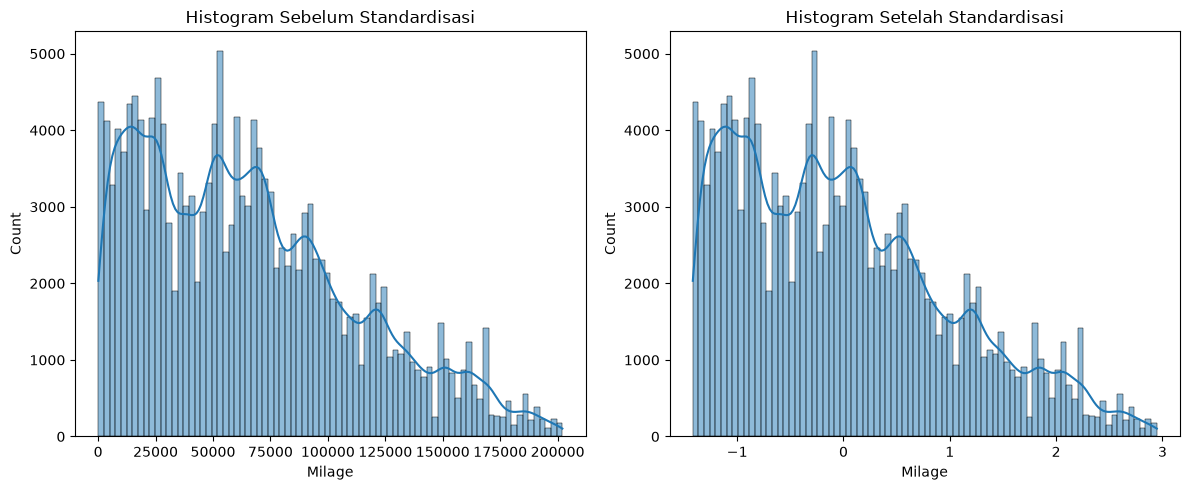

In [18]:
# Histogram sebelum dan sesudah standardisasi
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df["milage"], kde=True)
plt.title("Histogram Sebelum Standardisasi")
plt.xlabel("Milage")

plt.subplot(1, 2, 2)
sns.histplot(df_scaled["milage"], kde=True)
plt.title("Histogram Setelah Standardisasi")
plt.xlabel("Milage")

plt.tight_layout()
plt.show()

#### Memeriksa Data Duplikat

Pemeriksaan duplikasi dilakukan untuk mengetahui apakah terdapat baris data yang memiliki nilai identik. Duplikasi yang tidak diperlukan dapat memengaruhi hasil analisis sehingga perlu diperiksa sebelum proses pengolahan data dilanjutkan.

In [19]:
# Memeriksa jumlah baris duplikat
print("Duplikat pada data sebelum penyaringan outlier:", train.duplicated().sum())
print("Duplikat pada data setelah penyaringan outlier:", df.duplicated().sum())

Duplikat pada data sebelum penyaringan outlier: 0
Duplikat pada data setelah penyaringan outlier: 0


In [20]:
# Memilih kolom kategorikal pada data hasil penanganan outlier
categorical_features = df.select_dtypes(
    include=["object"]
).columns

print("Kolom kategorikal:")
print(list(categorical_features))

Kolom kategorikal:
['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']


C:\Users\jun\AppData\Local\Temp\ipykernel_13776\2879656562.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(


In [21]:
# Menghitung jumlah kategori unik pada setiap kolom kategorikal
for column in categorical_features:
    print(column, ":", df[column].nunique(), "kategori")

brand : 57 kategori
model : 1895 kategori
fuel_type : 7 kategori
engine : 1117 kategori
transmission : 52 kategori
ext_col : 318 kategori
int_col : 156 kategori
accident : 2 kategori
clean_title : 1 kategori


#### One-Hot Encoding

One-Hot Encoding digunakan untuk mengubah data kategorikal menjadi beberapa kolom bernilai biner. Metode ini diterapkan pada fitur dengan jumlah kategori yang relatif sedikit agar data dapat diproses oleh algoritma machine learning.

In [22]:
# One-Hot Encoding pada kolom dengan kategori sedikit
df_one_hot = pd.get_dummies(
    df,
    columns=["fuel_type", "accident"],
    dtype=int
)

df_one_hot.head()

,id,brand,model,model_year,milage,engine,transmission,ext_col,int_col,clean_title,price,fuel_type_Diesel,fuel_type_E85 Flex Fuel,fuel_type_Gasoline,fuel_type_Hybrid,fuel_type_Plug-In Hybrid,fuel_type_not supported,fuel_type_–,accident_At least 1 accident or damage reported,accident_None reported
3,3,Genesis,G90 5.0 Ultimate,2017,19500,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,Yes,45000,0,0,1,0,0,0,0,0,1
4,4,Mercedes-Benz,Metris Base,2021,7388,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,Yes,97500,0,0,1,0,0,0,0,0,1
5,5,Audi,A6 2.0T Sport,2018,40950,252.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,A/T,White,–,Yes,29950,0,0,1,0,0,0,0,0,1
6,6,Audi,A8 L 3.0T,2016,62200,333.0HP 3.0L V6 Cylinder Engine Gasoline Fuel,8-Speed A/T,Black,Black,Yes,28500,0,0,1,0,0,0,0,0,1
7,7,Chevrolet,Silverado 1500 1LZ,2016,102604,355.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,White,Gray,Yes,12500,0,1,0,0,0,0,0,0,1


#### Label Encoding

Label Encoding mengubah setiap kategori pada kolom kategorikal menjadi angka. Metode ini digunakan pada kolom dengan banyak kategori agar tidak menghasilkan terlalu banyak kolom baru seperti pada One-Hot Encoding.

In [23]:
from sklearn.preprocessing import LabelEncoder

# Menentukan kolom yang akan di-encode
label_features = [
    "brand",
    "model",
    "engine",
    "transmission",
    "ext_col",
    "int_col"
]

# Membuat salinan hasil One-Hot Encoding
df_lencoder = df_one_hot.copy()

# Melakukan Label Encoding
label_encoders = {}

for column in label_features:
    encoder = LabelEncoder()
    df_lencoder[column] = encoder.fit_transform(
        df_lencoder[column].astype(str)
    )
    label_encoders[column] = encoder

df_lencoder.head()

,id,brand,model,model_year,milage,engine,transmission,ext_col,int_col,clean_title,price,fuel_type_Diesel,fuel_type_E85 Flex Fuel,fuel_type_Gasoline,fuel_type_Hybrid,fuel_type_Plug-In Hybrid,fuel_type_not supported,fuel_type_–,accident_At least 1 accident or damage reported,accident_None reported
3,3,16,757,2017,19500,863,49,29,14,Yes,45000,0,0,1,0,0,0,0,0,1
4,4,36,1076,2021,7388,259,23,29,10,Yes,97500,0,0,1,0,0,0,0,0,1
5,5,3,182,2018,40950,364,38,303,155,Yes,29950,0,0,1,0,0,0,0,0,1
6,6,3,200,2016,62200,673,31,29,14,Yes,28500,0,0,1,0,0,0,0,0,1
7,7,9,1553,2016,102604,717,38,303,71,Yes,12500,0,1,0,0,0,0,0,0,1


In [24]:
# Memeriksa tipe data setelah encoding
df_lencoder.info()

<class 'pandas.DataFrame'>
Index: 171207 entries, 3 to 188532
Data columns (total 20 columns):
 #   Column                                           Non-Null Count   Dtype
---  ------                                           --------------   -----
 0   id                                               171207 non-null  int64
 1   brand                                            171207 non-null  int64
 2   model                                            171207 non-null  int64
 3   model_year                                       171207 non-null  int64
 4   milage                                           171207 non-null  int64
 5   engine                                           171207 non-null  int64
 6   transmission                                     171207 non-null  int64
 7   ext_col                                          171207 non-null  int64
 8   int_col                                          171207 non-null  int64
 9   clean_title                                      1712

In [25]:
# Menghapus kolom clean_title karena hanya memiliki satu kategori
df_lencoder = df_lencoder.drop(columns=["clean_title"])

# Memeriksa kembali struktur data
df_lencoder.info()

<class 'pandas.DataFrame'>
Index: 171207 entries, 3 to 188532
Data columns (total 19 columns):
 #   Column                                           Non-Null Count   Dtype
---  ------                                           --------------   -----
 0   id                                               171207 non-null  int64
 1   brand                                            171207 non-null  int64
 2   model                                            171207 non-null  int64
 3   model_year                                       171207 non-null  int64
 4   milage                                           171207 non-null  int64
 5   engine                                           171207 non-null  int64
 6   transmission                                     171207 non-null  int64
 7   ext_col                                          171207 non-null  int64
 8   int_col                                          171207 non-null  int64
 9   price                                            1712

#### Kesimpulan Data Cleaning dan Transformation

Pada tahap ini, dataset Car Prices diperiksa dan dibersihkan melalui penanganan missing values, penyaringan kandidat outlier menggunakan metode IQR, standardisasi fitur numerik, pemeriksaan duplikasi, serta encoding data kategorikal. Setelah proses tersebut, dataset memiliki 171.207 baris dan fitur yang siap digunakan untuk analisis eksploratif. Penyaringan outlier dilakukan berdasarkan batas IQR pada kolom `model_year`, `milage`, dan `price`.

#### 3. Latihan EDA & ExDA

In [26]:
df_lencoder.describe()

,id,brand,model,model_year,milage,engine,transmission,ext_col,int_col,price,fuel_type_Diesel,fuel_type_E85 Flex Fuel,fuel_type_Gasoline,fuel_type_Hybrid,fuel_type_Plug-In Hybrid,fuel_type_not supported,fuel_type_–,accident_At least 1 accident or damage reported,accident_None reported
count,171207.000000,171207.000000,171207.000000,171207.000000,171207.000000,171207.000000,171207.000000,171207.000000,171207.000000,171207.000000,171207.000000,171207.00000,171207.000000,171207.000000,171207.000000,171207.000000,171207.000000,171207.000000,171207.000000
mean,94252.318165,23.010443,869.705065,2016.114470,65686.246549,605.700684,29.679195,156.774168,34.399020,34141.905705,0.020899,0.03046,0.906639,0.036628,0.002979,0.000076,0.002319,0.226983,0.773017
std,54414.632598,15.834155,521.435574,4.986162,46275.429907,274.295259,13.042929,114.500787,39.421229,21320.883934,0.143046,0.17185,0.290938,0.187848,0.054498,0.008714,0.048099,0.418882,0.418882
min,3.000000,0.000000,0.000000,2003.000000,100.000000,0.000000,0.000000,0.000000,0.000000,2000.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47176.500000,9.000000,433.000000,2013.000000,26000.000000,383.000000,20.000000,29.000000,14.000000,17000.000000,0.000000,0.00000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,94191.000000,20.000000,816.000000,2017.000000,59459.000000,613.000000,32.000000,127.000000,14.000000,29998.000000,0.000000,0.00000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,141376.000000,36.000000,1319.000000,2020.000000,94653.000000,845.000000,38.000000,282.000000,31.000000,46000.000000,0.000000,0.00000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,188532.000000,56.000000,1894.000000,2024.000000,202055.000000,1116.000000,51.000000,317.000000,155.000000,99000.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


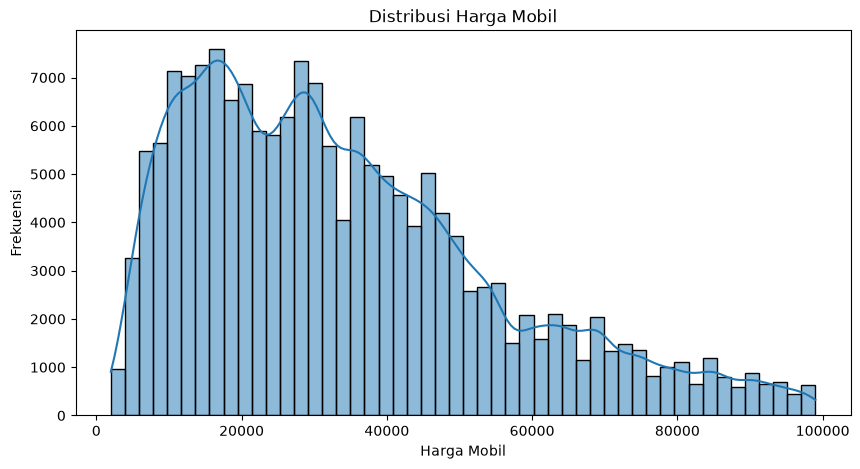

In [27]:
# Menampilkan distribusi harga mobil
plt.figure(figsize=(10, 5))
sns.histplot(df_lencoder["price"], bins=50, kde=True)

plt.title("Distribusi Harga Mobil")
plt.xlabel("Harga Mobil")
plt.ylabel("Frekuensi")
plt.show()

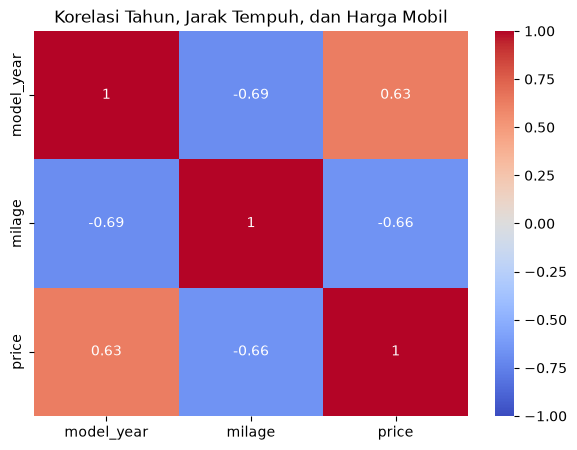

In [28]:
# Memilih fitur numerik utama untuk analisis korelasi
corr_features = [
    "model_year",
    "milage",
    "price"
]

# Menghitung korelasi
correlation = df_lencoder[corr_features].corr()

# Membuat heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Korelasi Tahun, Jarak Tempuh, dan Harga Mobil")
plt.show()

Mendekati 1: hubungan positif kuat.
Mendekati -1: hubungan negatif kuat.
Mendekati 0: hubungan linear lemah.

#### Kesimpulan EDA & ExDA

Hasil analisis menunjukkan bahwa distribusi harga mobil cenderung miring ke kanan. Korelasi menunjukkan bahwa tahun model berhubungan positif dengan harga (0,63), sedangkan jarak tempuh berhubungan negatif dengan harga (-0,66). Artinya, mobil yang lebih baru dan memiliki jarak tempuh lebih rendah cenderung berharga lebih tinggi.

#### 4. Latihan Data Splitting

In [29]:
from sklearn.model_selection import train_test_split

# Memisahkan fitur dan target
X = df_lencoder.drop(columns=["price", "id"])
y = df_lencoder["price"]

# Membagi data menjadi data latih dan data uji
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

print("Jumlah data:", len(X))
print("Jumlah data latih:", len(x_train))
print("Jumlah data uji:", len(x_test))

Jumlah data: 171207
Jumlah data latih: 136965
Jumlah data uji: 34242


#### Kesimpulan Data Splitting

Dataset Car Prices berhasil dibagi menjadi 80% data latih sebanyak 136.965 baris dan 20% data uji sebanyak 34.242 baris. Fitur (`X`) dan target (`y`), yaitu `price`, telah dipisahkan untuk persiapan pemodelan machine learning.

In [ ]:
for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=train[feature])
    plt.title(f"Box Plot of {feature}")
    plt.show()
 
# menghitung batas outlier dengan IQR (tanpa kolom id)
outlier_features = ["model_year", "milage", "price"]
Q1 = train[outlier_features].quantile(0.25)
Q3 = train[outlier_features].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
 
condition_outlier = ((train[outlier_features] < lower_bound) |
                    (train[outlier_features] > upper_bound))
condition = ~condition_outlier.any(axis=1)
 
# DataFrame baru tanpa baris outlier
df = train.loc[condition].copy()

